# BatteryIQ — Phase 2: SHAP Explainability Analysis

**Member 3 | Branch:** `feature/condition-shap`

---

## Objective
Provide explainable AI analysis for a **validated BatteryIQ RUL XGBoost model** using SHAP (SHapley Additive exPlanations).

## SHAP Implementation Rules
- Explain predictions from an actual **LOGO validation fold model**.
- Use the exact frozen feature set from the ML contract.
- Preserve exact feature order.
- Ensure no target leakage.
- No fake models, placeholder predictions, or fabricated SHAP values.

## Model Being Explained
This notebook trains the same XGBoost configuration used by the BatteryIQ RUL baseline and selects one **Leave-One-Battery-Out (LOGO)** fold for SHAP analysis.

The selected fold is generated programmatically. The held-out battery is never used to fit the model or the SHAP background data.


---
## 0. Imports & Setup


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the BatteryIQ repository root robustly.
PROJECT_ROOT = Path.cwd()

while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").exists():
    raise RuntimeError(
        "Could not locate the BatteryIQ repository root. "
        "Run this notebook from inside the repository."
    )

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Repository root:", PROJECT_ROOT)


Repository root: d:\VIT Academic\TY\sem 5\EDI\BatteryIQ


In [2]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
try:
    import shap
    print("✅ SHAP is available")
    print("   SHAP version:", shap.__version__)
except ImportError as exc:
    raise ImportError(
        "SHAP is not installed. Install it with: pip install shap"
    ) from exc

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

from explainability.shap_analysis import (
    SHAPAnalyzer,
    validate_feature_matrix,
    FROZEN_FEATURE_COLUMNS,
)

print("✅ All imports successful")


✅ SHAP is available
   SHAP version: 0.49.1
✅ All imports successful


---
## 1. Load and Prepare the Frozen Datasets


In [4]:
FEATURES_FILE = PROJECT_ROOT / "data" / "features" / "battery_cycle_features.csv"
RUL_FILE = PROJECT_ROOT / "data" / "features" / "rul_targets.csv"

for file_path in [FEATURES_FILE, RUL_FILE]:
    if not file_path.exists():
        raise FileNotFoundError(f"Required file not found: {file_path}")
    print(f"✅ {file_path.relative_to(PROJECT_ROOT)}")

features_df = pd.read_csv(FEATURES_FILE)
rul_df = pd.read_csv(RUL_FILE)

model_df = features_df.merge(
    rul_df,
    on=["battery_id", "cycle"],
    how="inner",
)

# B0007 is right-censored and therefore has no supervised RUL target.
model_df = model_df[model_df["rul_valid"] == True].copy()

if model_df.empty:
    raise ValueError("No valid RUL rows remain after merging/filtering.")

model_df = model_df.sort_values(["battery_id", "cycle"]).reset_index(drop=True)

print("Merged valid-RUL dataset shape:", model_df.shape)
print("Batteries used:", sorted(model_df["battery_id"].unique()))
print("B0007 present in supervised data:", "B0007" in set(model_df["battery_id"]))


✅ data\features\battery_cycle_features.csv
✅ data\features\rul_targets.csv
Merged valid-RUL dataset shape: (331, 19)
Batteries used: ['B0005', 'B0006', 'B0018']
B0007 present in supervised data: False


In [5]:
# Extract the exact frozen predictor matrix and RUL target.
X = model_df[FROZEN_FEATURE_COLUMNS].copy()
y = pd.to_numeric(model_df["rul"], errors="raise")
groups = model_df["battery_id"].copy()

validate_feature_matrix(X)

if y.isnull().any():
    raise ValueError("RUL target contains missing values.")

if (y < 0).any():
    raise ValueError("Negative RUL values detected.")

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Number of frozen features: {len(FROZEN_FEATURE_COLUMNS)}")
print("\nFrozen feature order:")
for i, feature in enumerate(FROZEN_FEATURE_COLUMNS, start=1):
    print(f"  {i:2d}. {feature}")


X shape: (331, 15)
y shape: (331,)
Number of frozen features: 15

Frozen feature order:
   1. voltage_mean
   2. voltage_min
   3. voltage_max
   4. voltage_std
   5. current_mean
   6. current_min
   7. current_max
   8. temperature_mean
   9. temperature_max
  10. current_load_mean
  11. voltage_load_mean
  12. cycle_time
  13. voltage_change
  14. temperature_change
  15. temperature_rolling_mean


---
## 2. Leakage and Feature-Contract Checks


In [6]:
prohibited_keywords = [
    "capacity",
    "soh",
    "rul",
    "retention",
    "degradation",
]

found_prohibited = [
    col for col in X.columns
    if any(keyword in col.lower() for keyword in prohibited_keywords)
]

if found_prohibited:
    raise ValueError(
        f"Target leakage detected in predictor features: {found_prohibited}"
    )

if X.columns.tolist() != FROZEN_FEATURE_COLUMNS:
    raise ValueError("Feature order does not match the frozen ML contract.")

if X.isnull().any().any():
    raise ValueError("Predictor matrix contains missing values.")

print("✅ Exact frozen 15-feature set confirmed")
print("✅ Exact feature order confirmed")
print("✅ No capacity/SOH/RUL leakage detected")
print("✅ No missing predictor values")


✅ Exact frozen 15-feature set confirmed
✅ Exact feature order confirmed
✅ No capacity/SOH/RUL leakage detected
✅ No missing predictor values


---
## 3. LOGO Validation Fold Selection

The RUL baseline uses Leave-One-Battery-Out validation.  
For SHAP, we explain an **actual model from one LOGO fold** rather than fitting a model on all batteries.

The held-out battery is selected programmatically from the available LOGO folds.


In [7]:
logo = LeaveOneGroupOut()

folds = list(logo.split(X, y, groups=groups))
if not folds:
    raise ValueError("LOGO produced no folds.")

# Use the final LOGO fold for the SHAP demonstration.
# The fold assignment itself is generated programmatically.
fold_number = len(folds)
train_idx, test_idx = folds[-1]

train_batteries = sorted(groups.iloc[train_idx].unique().tolist())
test_batteries = sorted(groups.iloc[test_idx].unique().tolist())

if len(test_batteries) != 1:
    raise ValueError("Expected exactly one held-out battery in the LOGO test fold.")

test_battery = test_batteries[0]

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print(f"Selected LOGO fold: {fold_number}")
print(f"Training batteries: {train_batteries}")
print(f"Held-out test battery: {test_battery}")
print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")

if set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]):
    raise ValueError("Battery leakage detected between train and test.")

print("✅ No battery appears in both train and held-out test sets")


Selected LOGO fold: 3
Training batteries: ['B0005', 'B0006']
Held-out test battery: B0018
Training rows: 234
Test rows: 97
✅ No battery appears in both train and held-out test sets


---
## 4. Train the Validated RUL XGBoost Fold Model


In [8]:
model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    verbosity=0,
)

model.fit(X_train, y_train)

test_predictions = model.predict(X_test)

fold_mae = mean_absolute_error(y_test, test_predictions)
fold_rmse = float(np.sqrt(mean_squared_error(y_test, test_predictions)))
fold_r2 = r2_score(y_test, test_predictions)

print("✅ LOGO fold model trained")
print(f"Test battery: {test_battery}")
print(f"MAE : {fold_mae:.4f}")
print(f"RMSE: {fold_rmse:.4f}")
print(f"R²  : {fold_r2:.4f}")


✅ LOGO fold model trained
Test battery: B0018
MAE : 16.5150
RMSE: 19.9345
R²  : 0.4931


### Validation note

These metrics are the **held-out LOGO metrics for the selected fold**. They are not training-set metrics.

The SHAP analysis below explains predictions made by this same held-out-fold model on its unseen test battery.


---
## 5. SHAP Analyzer Initialization

The SHAP background dataset is drawn **only from the training batteries**.  
The held-out battery is reserved for explanation/evaluation and is not used as SHAP background data.


In [9]:
analyzer = SHAPAnalyzer(
    model=model,
    feature_matrix=X_test,
    feature_names=FROZEN_FEATURE_COLUMNS,
)

# Fit the SHAP background explainer using training-battery data only.
background_size = min(100, len(X_train))
background_X = X_train.sample(
    n=background_size,
    random_state=42,
).copy()

# SHAPAnalyzer.fit_explainer() uses its feature_matrix as background.
# Create a separate analyzer with the training-only background while
# retaining the held-out X_test for the actual explanations below.
background_analyzer = SHAPAnalyzer(
    model=model,
    feature_matrix=background_X,
    feature_names=FROZEN_FEATURE_COLUMNS,
)

background_analyzer.fit_explainer(background_sample_size=background_size)
background_analyzer.compute_shap_values(X_test)

# Use the held-out test matrix as the analyzer's feature matrix so
# local/global methods operate on unseen-battery predictions.
background_analyzer.feature_matrix = X_test.copy()

analyzer = background_analyzer

print("✅ SHAP analyzer initialized")
print(f"   Model type: {type(model).__name__}")
print(f"   Background rows: {background_size}")
print(f"   Held-out rows explained: {len(X_test)}")


  0%|          | 0/97 [00:00<?, ?it/s]

✅ SHAP analyzer initialized
   Model type: XGBRegressor
   Background rows: 100
   Held-out rows explained: 97


In [10]:
# Compute and inspect SHAP values for the held-out battery.
shap_values = analyzer.shap_values

if shap_values is None:
    raise ValueError("SHAP values were not computed.")

print("SHAP value shape:", np.asarray(shap_values).shape)
print("Held-out feature matrix shape:", X_test.shape)
print("✅ SHAP explanations correspond to the held-out LOGO battery")


SHAP value shape: (97, 15)
Held-out feature matrix shape: (97, 15)
✅ SHAP explanations correspond to the held-out LOGO battery


---
## 6. Global SHAP Feature Importance


In [11]:
importance_df = analyzer.get_global_feature_importance()

print("Global Feature Importance for the held-out LOGO fold:")
print(importance_df.to_string(index=False))


Global Feature Importance for the held-out LOGO fold:
                 feature  importance
       voltage_load_mean    8.860734
              cycle_time    6.724554
temperature_rolling_mean    4.419758
            voltage_mean    3.063801
         temperature_max    1.470675
       current_load_mean    0.908022
            current_mean    0.832742
        temperature_mean    0.398992
             voltage_max    0.291670
             voltage_min    0.126983
          voltage_change    0.085777
             voltage_std    0.073669
      temperature_change    0.042289
             current_max    0.014509
             current_min    0.005908


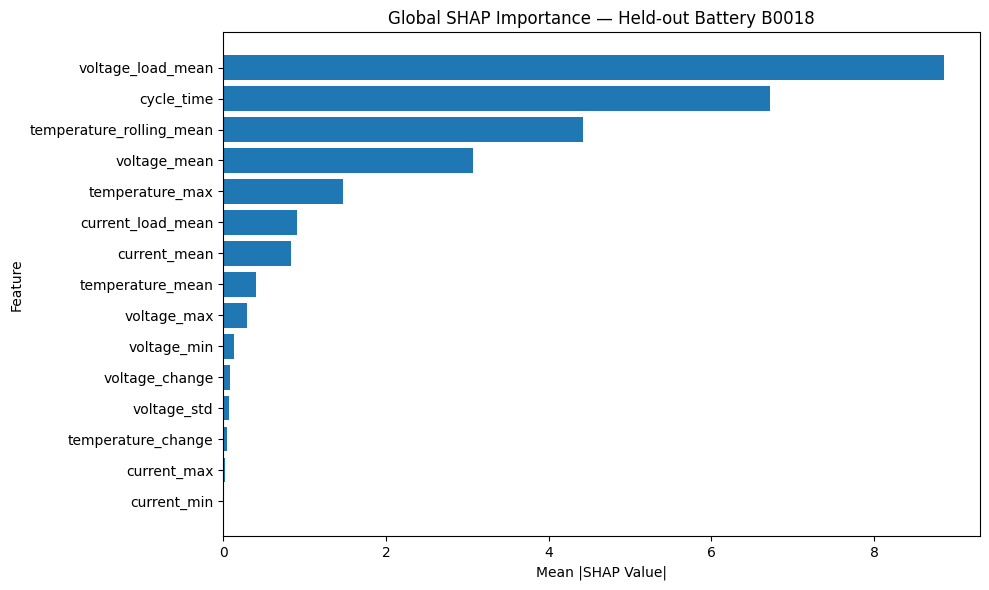

In [12]:
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["feature"],
    importance_df["importance"],
)
plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")
plt.title(f"Global SHAP Importance — Held-out Battery {test_battery}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


---
## 7. SHAP Summary Plot


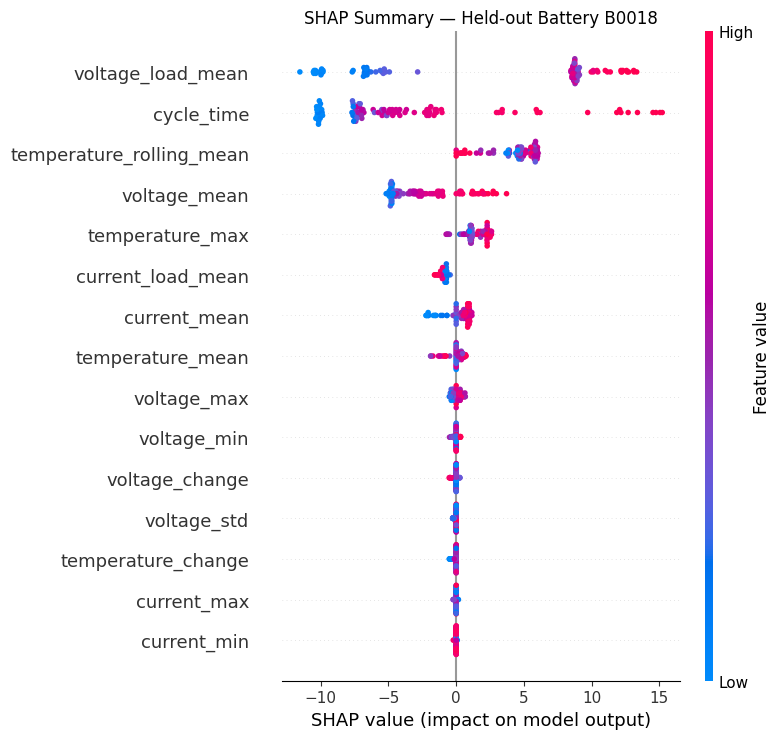

In [13]:
shap_vals, feature_vals = analyzer.get_summary_data()

plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_vals,
    feature_vals,
    feature_names=FROZEN_FEATURE_COLUMNS,
    show=False,
)
plt.title(f"SHAP Summary — Held-out Battery {test_battery}")
plt.tight_layout()
plt.show()


---
## 8. Individual Held-Out Prediction Explanation


In [14]:
sample_idx = 0
explanation = analyzer.explain_prediction(sample_idx)

print(f"Explanation for held-out sample {sample_idx}")
print(f"Battery: {test_battery}")
print(f"Cycle: {int(model_df.iloc[test_idx[sample_idx]]['cycle'])}")
print(f"Actual RUL: {y_test.iloc[sample_idx]:.2f} cycles")
print(f"Predicted RUL: {explanation['prediction']:.2f} cycles")

if explanation["base_value"] is not None:
    print(f"Base value: {explanation['base_value']:.2f} cycles")

print("\nTop feature contributions:")
contributions = explanation["feature_contributions"]
sorted_contrib = sorted(
    contributions.items(),
    key=lambda item: abs(item[1]["shap_value"]),
    reverse=True,
)

for rank, (feature, values) in enumerate(sorted_contrib[:10], start=1):
    direction = "+" if values["shap_value"] > 0 else ""
    print(
        f"  {rank:2d}. {feature:30s}: "
        f"{direction}{values['shap_value']:8.3f} "
        f"(feature value: {values['feature_value']:.3f})"
    )


Explanation for held-out sample 0
Battery: B0018
Cycle: 1
Actual RUL: 96.00 cycles
Predicted RUL: 81.77 cycles
Base value: 57.64 cycles

Top feature contributions:
   1. cycle_time                    : +  14.749 (feature value: 3434.891)
   2. voltage_load_mean             : +  12.731 (feature value: 2.568)
   3. current_mean                  :   -1.595 (feature value: -1.954)
   4. temperature_max               : +   1.550 (feature value: 38.102)
   5. current_load_mean             :   -1.406 (feature value: 1.944)
   6. voltage_mean                  :   -1.155 (feature value: 3.528)
   7. temperature_mean              :   -0.930 (feature value: 31.773)
   8. temperature_rolling_mean      : +   0.636 (feature value: 31.773)
   9. voltage_max                   :   -0.268 (feature value: 4.188)
  10. voltage_std                   :   -0.190 (feature value: 0.236)


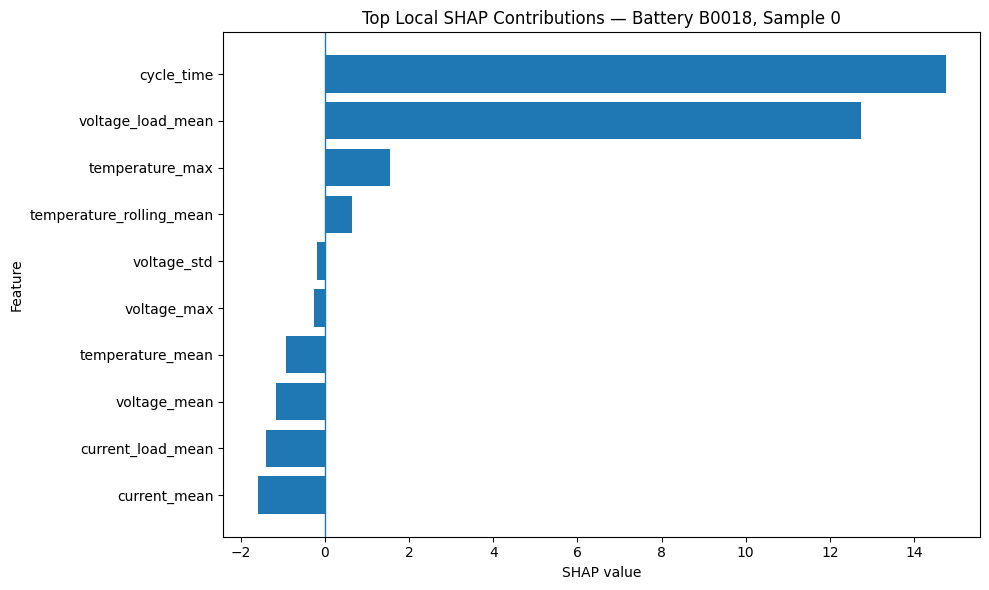

In [15]:
# Compact local contribution plot for the same held-out prediction.
top_contrib = pd.DataFrame(
    [
        {
            "feature": feature,
            "shap_value": values["shap_value"],
        }
        for feature, values in sorted_contrib[:10]
    ]
).sort_values("shap_value")

plt.figure(figsize=(10, 6))
plt.barh(top_contrib["feature"], top_contrib["shap_value"])
plt.axvline(0, linewidth=1)
plt.xlabel("SHAP value")
plt.ylabel("Feature")
plt.title(
    f"Top Local SHAP Contributions — "
    f"Battery {test_battery}, Sample {sample_idx}"
)
plt.tight_layout()
plt.show()


---
## 9. Verification Checks


In [16]:
# Verify that the analyzer's prediction matches the model prediction.
direct_prediction = model.predict(X_test.iloc[[sample_idx]])[0]
shap_prediction = analyzer.explain_prediction(sample_idx)["prediction"]

print(f"Direct model prediction: {direct_prediction:.6f}")
print(f"SHAP explanation prediction: {shap_prediction:.6f}")
print(f"Difference: {abs(direct_prediction - shap_prediction):.10f}")

if np.isclose(direct_prediction, shap_prediction, atol=1e-8):
    print("✅ SHAP explanation uses the actual model prediction")
else:
    raise AssertionError("SHAP prediction does not match model prediction.")


Direct model prediction: 81.766380
SHAP explanation prediction: 81.766380
Difference: 0.0000000000
✅ SHAP explanation uses the actual model prediction


In [17]:
# Verify the predictor matrix contains no target columns.
target_keywords = ["capacity", "soh", "rul", "target"]
found_targets = [
    col for col in X_test.columns
    if any(keyword in col.lower() for keyword in target_keywords)
]

if found_targets:
    raise AssertionError(f"Target leakage detected: {found_targets}")

print("✅ No target columns in predictor matrix")
print("✅ Exact frozen feature order preserved")
print("✅ Held-out battery was excluded from model training")
print("✅ Held-out battery was excluded from SHAP background data")


✅ No target columns in predictor matrix
✅ Exact frozen feature order preserved
✅ Held-out battery was excluded from model training
✅ Held-out battery was excluded from SHAP background data


---
## 10. Summary


In [18]:
print("=" * 65)
print("  BatteryIQ Phase 2 — SHAP Analysis Summary")
print("=" * 65)

print(f"\nModel Explained: XGBoost RUL Regressor")
print(f"Validation: Leave-One-Battery-Out (LOGO)")
print(f"Selected LOGO fold: {fold_number}")
print(f"Training batteries: {train_batteries}")
print(f"Held-out battery: {test_battery}")
print(f"Target: Remaining Useful Life (cycles)")
print(f"Feature Set: {len(FROZEN_FEATURE_COLUMNS)} frozen predictors")

print("\nSelected LOGO metrics:")
print(f"  MAE : {fold_mae:.4f}")
print(f"  RMSE: {fold_rmse:.4f}")
print(f"  R²  : {fold_r2:.4f}")

print("\nTop 5 SHAP features:")
for i, row in importance_df.head(5).iterrows():
    print(f"  {i + 1}. {row['feature']:30s}: {row['importance']:.4f}")

print("\nVerification Status:")
print("  ✅ Actual LOGO fold model explained")
print("  ✅ Held-out battery not used for training")
print("  ✅ Held-out battery not used as SHAP background")
print("  ✅ Exact frozen 15-feature set")
print("  ✅ Exact feature order preserved")
print("  ✅ No target leakage")
print("  ✅ SHAP prediction matches direct model prediction")
print("  ✅ Global and local explanations generated")

print("\n" + "=" * 65)


  BatteryIQ Phase 2 — SHAP Analysis Summary

Model Explained: XGBoost RUL Regressor
Validation: Leave-One-Battery-Out (LOGO)
Selected LOGO fold: 3
Training batteries: ['B0005', 'B0006']
Held-out battery: B0018
Target: Remaining Useful Life (cycles)
Feature Set: 15 frozen predictors

Selected LOGO metrics:
  MAE : 16.5150
  RMSE: 19.9345
  R²  : 0.4931

Top 5 SHAP features:
  1. voltage_load_mean             : 8.8607
  2. cycle_time                    : 6.7246
  3. temperature_rolling_mean      : 4.4198
  4. voltage_mean                  : 3.0638
  5. temperature_max               : 1.4707

Verification Status:
  ✅ Actual LOGO fold model explained
  ✅ Held-out battery not used for training
  ✅ Held-out battery not used as SHAP background
  ✅ Exact frozen 15-feature set
  ✅ Exact feature order preserved
  ✅ No target leakage
  ✅ SHAP prediction matches direct model prediction
  ✅ Global and local explanations generated

